In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import eigs, eigsh
from scipy import linalg
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import accuracy_score
from scipy.optimize import linear_sum_assignment

In [36]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh

def bethe_hessian_matrix(A, r):
    """
    Compute the Bethe Hessian matrix for a given adjacency matrix A and regularizer r.
    
    Args:
    A (scipy sparse matrix): adjacency matrix
    r (float): regularization parameter
    
    Returns:
    H (scipy sparse matrix): Bethe Hessian matrix
    """
    degrees = np.sum(A, axis=1)
    n = A.shape[0]
    
    # Create a diagonal degree matrix
    D = diags(degrees)
    
    # Bethe Hessian matrix: H = (r^2 - 1) * I - r * A + D
    H = (r**2 - 1) * np.identity(n) - r * A + D
    
    return H

def estimate_number_of_communities(A, t):
    """
    Estimate the number of communities in a network using the Bethe Hessian matrix.
    
    Args:
    A (scipy sparse matrix): adjacency matrix
    
    Returns:
    int: estimated number of communities
    """
    n = A.shape[0]
    degrees = np.sum(A, axis=1)
    # Compute the average degree (used to set the regularizer r)
    avg_degree = np.mean(A.sum(axis=1))
    
    # Set the regularization parameter r
    r = np.sqrt(avg_degree)
    # r = np.sqrt(np.sum(degrees**2) / np.sum(degrees) - 1)

    # Compute the Bethe Hessian matrix
    H = bethe_hessian_matrix(A, r)
    
    # Compute the eigenvalues of the Bethe Hessian matrix
    eigvals = linalg.eigvals(H)
    eigvals = np.sort(eigvals)[::-1]

    # # plot the eigenvalues
    # plt.plot(eigvals.real, eigvals.imag, 'o')
    # plt.xlabel('Re')
    # plt.ylabel('Im')
    # plt.title('Eigenvalues of the Bethe Hessian matrix')
    # plt.show()
    
    # Count the number of communities based on the eigenvalues
    for k in range(len(eigvals)-1, 0, -1):
        if eigvals[n - k] >= t * eigvals[n - k + 1]:
            return k
    
    return 0

In [37]:
# cites_file = "Datasets/citeseer-doc-classification/citeseer.cites"
# content_file = "Datasets/citeseer-doc-classification/citeseer.content"
# A, features, actual_labels = parse_dataset(cites_file, content_file)
# k1 = estimate_number_of_communities(A)
# print(f"Estimated number of communities using Bethes Hessian: {k1}")
# # k2 = estimate_num_communities(A)
# # print(f"Estimated number of communities using Non-Backtracking: {k2}")

In [47]:
# Non-backtracking matrix-based method to estimate number of communities
def estimate_num_communities(A, initial_k=4, step=1, max_k=10):
    # Step 1: Calculate the degrees of the nodes
    degrees = np.sum(A, axis=1)
    diag_degrees = diags(degrees)
    
    # Step 2: Construct the non-backtracking matrix
    non_backtracking_matrix = np.block([
        [np.zeros_like(A), diag_degrees - np.identity(len(A))],
        [-np.identity(len(A)), A]
    ])
    
    # Step 3: Compute the norm of the non-backtracking matrix
    # radius = np.sqrt(np.linalg.norm(non_backtracking_matrix, ord=2))
    radius = np.sqrt(np.sum(degrees**2) / np.sum(degrees) - 1) # Approximation of the spectral radius
    print("Radius of the non-backtracking matrix:", radius)
    # radius = np.sqrt(np.sum(np.abs(non_backtracking_matrix.data)**2))

    k = initial_k
    communities_count = 0
    all_real_found = False

    eigvals = linalg.eigvals(non_backtracking_matrix)
    # eigvals = np.sort(eigvals)[::-1]
    # print the eigenvalues in a file
    np.savetxt('eigenvalues.txt', eigvals)
    # plot the eigenvalues
    plt.plot(eigvals.real, eigvals.imag, 'o')
    plt.xlabel('Re')
    plt.ylabel('Im')
    plt.title('Eigenvalues of the non-backtracking matrix')
    plt.show()

    # count number of real eigenvalues that are greater than or equal to the radius
    communities_count = len([eig for eig in eigvals if np.isclose(eig.imag, 0) and abs(eig.real) >= radius])

    return communities_count

# Function to initialize P randomly
def initialize_P(n, k):
    P = np.abs(np.random.rand(n, k))
    for i in range(n):
        if np.sum(P[i]) == 0:
            P[i] = np.ones(k) / k
        else:
            P[i] /= np.sum(P[i])
    return P

# Symmetric NMF update rule
def update_P(Lz, P, beta=0.5):
    numerator = np.dot(Lz, P)
    denominator = np.dot(np.dot(P, P.T), P)
    denominator[denominator == 0] = 1e-10  # Avoid division by zero
    P = P * ((1 - beta) + beta * numerator / denominator)
    P_updated = np.maximum(np.dot(np.dot(Lz, P), np.linalg.inv(np.dot(P.T, P))), 0) # Non-negative constraint
    return P_updated

def calculate_ipr(vector):
    """
    Calculate the Inverse Participation Ratio (IPR) for a given vector.
    IPR is the sum of the fourth power of the elements in the vector.
    """
    return np.sum(vector**4)

def update_regularization_matrix(Z, feature_matrix, threshold=0.1):
    """
    Update the diagonal elements of matrix Z based on the IPR of the feature vectors.
    A penalty is applied if the IPR exceeds a certain threshold (indicating high localization).
    
    Parameters:
    - Z: Initial regularization matrix (diagonal, 4x4 in this case for 4 nodes).
    - feature_matrix: The matrix where each row is a feature vector (10x4).
    - threshold: A value to decide when to apply a penalty based on IPR.
    """
    for i, vector in enumerate(feature_matrix):  # Iterate over the columns (nodes' feature vectors)
        ipr_value = calculate_ipr(vector)
        if ipr_value > threshold:
            # print(f"Node {i} has high IPR ({ipr_value}), applying penalty.")
            # Apply a penalty by modifying the diagonal element of Z
            Z[i, i] -= ipr_value  # Example penalty: increase the diagonal element by 1
    return Z

# Function to reduce the rank of a matrix to target rank k
def reduce_matrix_rank(A, target_rank):
    # Step 1: Perform Singular Value Decomposition (SVD)
    U, S, VT = np.linalg.svd(A, full_matrices=False)
    
    # Step 2: Keep only the top 'target_rank' singular values
    S_reduced = np.zeros((target_rank, target_rank))
    np.fill_diagonal(S_reduced, S[:target_rank])
    
    # Reduce U and VT to keep only the columns and rows associated with top singular values
    U_reduced = U[:, :target_rank]
    VT_reduced = VT[:target_rank, :]
    
    # Step 3: Reconstruct the matrix with reduced rank
    A_reduced = U_reduced @ S_reduced @ VT_reduced
    
    return A_reduced

def learn_regularization_matrix(Lz, k, num_iterations=5):
    for _ in range(num_iterations):
        rank = np.linalg.matrix_rank(Lz)
        print(f"Rank of the Laplacian matrix: {rank}")
        
        eigenvalues, eigenvectors = np.linalg.eig(Lz)
        # # Sort the eigenvectors based on the eigenvalues in descending order
        # idx = eigenvalues.argsort()[::-1]
        # eigenvalues = eigenvalues[idx]
        # eigenvectors = eigenvectors[:, idx]

        # # Find the localised eigenvectors using inverse participation ratio (IPR)
        # ipr_values = []
        # for i in range(len(eigenvectors.T)):
        #     ipr_values.append(calculate_ipr(eigenvectors.T[i]))

        # # Drop the eigenvectors with high IPR
        # threshold = np.mean(ipr_values)
        # print(f"Threshold for IPR: {threshold}")
        # high_ipr = ipr_values > threshold
        # for i in range(len(ipr_values)):
        #     if ipr_values[i] > threshold:
        #         eigenvalues[i] = 0
        # print(f"Number of eigenvectors with high IPR: {np.sum(high_ipr)}")

        # Drop the negative eigenvalues and their corresponding eigenvectors
        neg_eigenvals = eigenvalues < 0
        print(f"Total eigenvalues: {len(eigenvalues)}")
        print(f"Zero eigenvalues: {np.sum(np.isclose(eigenvalues, 0))}")
        print(f"Negative eigenvalues: {np.sum(neg_eigenvals)}")
        for i in range(len(eigenvalues)):
            if neg_eigenvals[i]:
                eigenvalues[i] = 0

        # Reconstruction of the Laplacian matrix
        Lz = np.dot(np.dot(eigenvectors, np.diag(eigenvalues)), eigenvectors.T)
    
    return Lz

# CDNMF algorithm
def CDNMF(A, features, k, num_iterations=100, beta=0.5):
    n = A.shape[0]
    
    # Step 1: Estimate the number of communities (k) using spectral analysis
    # k = estimate_num_communities(A)
    # k = 8  # For simplicity, we will use a fixed number of communities
    print(f"Estimated number of communities: {k}")
    
    # Step 2: Initialize P matrix randomly
    P = initialize_P(n, k)
    
    # Step 3: Initialize regularization matrix Z
    Z = np.zeros_like(A)
    Lz = A + Z
    # Z = update_regularization_matrix(Z, features, threshold=0.001)
    Lz = learn_regularization_matrix(Lz, k, num_iterations=5)
    # Lz = reduce_matrix_rank(Lz, k)

    # Step 4: Iteratively update P using the update rule
    prev_obj_value = -np.inf
    threshold_value = np.linalg.norm(A - np.dot(P, P.T), 'fro') * 1e-5
    for iteration in range(num_iterations):
        P = update_P(Lz, P, beta)

        # Compute the objective function value
        obj_value = np.linalg.norm(A - np.dot(P, P.T), 'fro')
        if iteration % 10 == 0:
            print(f"Objective function value after {iteration+1} iterations: {obj_value}")

        # If the change in objective value is below a certain threshold, stop the iterations
        if abs(prev_obj_value - obj_value) < 1e-5:
            print(f"Converged after {iteration+1} iterations.")
            break
        prev_obj_value = obj_value

    # Normalize P so that each row sums to 1
    # if some rows are all zeros, set them to uniform distribution
    for i in range(n):
        if np.sum(P[i]) == 0:
            P[i] = np.ones(k) / k
        else:
            P[i] /= np.sum(P[i])
    
    # Assign nodes to communities based on maximum membership value
    communities = np.argmax(P, axis=1)
    
    return communities, P


In [41]:
# Function to parse .cites and .content files and build the adjacency matrix
def parse_dataset(cites_file, content_file):
    # Parse the .content file
    features = []
    node_id_to_index = {}
    class_labels = {}
    actual_labels = []
    num_nodes = 0
    with open(content_file, "r") as file:
        for line in file:
            parts = line.strip().split("\t")
            node_id = parts[0]
            node_id_to_index[node_id] = num_nodes

            feature_vector = np.array([float(x) for x in parts[1:-1]])
            feature_vector = feature_vector / np.linalg.norm(feature_vector)
            features.append(feature_vector)

            class_label = parts[-1]
            if class_label not in class_labels:
                class_labels[class_label] = len(class_labels)
            actual_labels.append(class_labels[class_label])
            
            num_nodes += 1

    # make number of features consistent
    max_features = max([len(feature) for feature in features])
    for i in range(len(features)):
        features[i] = np.pad(features[i], (0, max_features - len(features[i])), 'constant')
    
    features = np.array(features)

    # Parse the .cites file
    edges = []
    with open(cites_file, "r") as file:
        for line in file:
            parts = line.strip().split("\t")
            edges.append((parts[0], parts[1]))
    
    # Build the adjacency matrix
    A = np.zeros((num_nodes, num_nodes))
    for edge in edges:
        if edge[0] not in node_id_to_index or edge[1] not in node_id_to_index:
            # print(f"Node not found: {edge[0]} or {edge[1]}")
            continue
        x = node_id_to_index[edge[0]]
        y = node_id_to_index[edge[1]]
        A[x, y] = 1
        A[y, x] = 1
        # print(f"Adding edge between {x} and {y}")

    # # Remove rows and columns with all zeros
    # degrees = np.sum(A, axis=1)
    # zero_rows = np.where(degrees == 0)[0]
    # A = np.delete(A, zero_rows, axis=0)
    # zero_cols = np.where(np.sum(A, axis=0) == 0)[0]
    # A = np.delete(A, zero_cols, axis=1)
    
    print(f"Number of nodes: {A.shape[0]}")
    print(f"Number of edges: {np.sum(A) // 2}")
    print(f"Feature dimension: {len(features[0])}")
    print(f"Number of unique class labels: {len(class_labels)}")

    # # Count number of isolated nodes
    # isolated_nodes = np.where(np.sum(A, axis=1) == 0)[0]
    # print(f"Number of isolated nodes: {len(isolated_nodes)}")

    # # Convert directed graph to undirected graph by duplicating the nodes
    # A = np.zeros((2*num_nodes, 2*num_nodes))
    # for edge in edges:
    #     if edge[0] not in node_id_to_index or edge[1] not in node_id_to_index:
    #         continue
    #     x = node_id_to_index[edge[0]]
    #     y = node_id_to_index[edge[1]]
    #     A[x, y] = 1
    #     A[y, x] = 1
    #     A[x, x+num_nodes] = 1
    #     A[x+num_nodes, x] = 1
    #     A[y, y+num_nodes] = 1
    #     A[y+num_nodes, y] = 1
    #     A[x+num_nodes, y+num_nodes] = 1
    #     A[y+num_nodes, x+num_nodes] = 1
    #     A[x, y+num_nodes] = 1
    #     A[y+num_nodes, x] = 1

    # features = np.concatenate((features, features), axis=0)
    # actual_labels = actual_labels + actual_labels
    
    return A, features, actual_labels

In [42]:
def calculate_modularity(A, communities):
    """
    Calculate modularity of a graph with adjacency matrix A and community assignments.
    
    A: numpy array (adjacency matrix)
    communities: list or array of community assignments for each node
    """
    num_nodes = A.shape[0]
    m = np.sum(A) // 2  # Total number of edges in the graph
    modularity = 0.0

    # Calculate degree of each node
    degrees = np.sum(A, axis=1)
    
    for i in range(num_nodes):
        for j in range(num_nodes):
            if communities[i] == communities[j]:  # Only consider nodes in the same community
                modularity += float(A[i, j]) - float(degrees[i] * degrees[j]) / float(2 * m)
    
    return modularity / (2 * m)

In [7]:
from math import comb

# Function to compute the Adjusted Rand Index (ARI)
def adjusted_rand_index(labels_true, labels_pred):
    n = len(labels_true)
    
    # Create contingency table (confusion matrix)
    contingency = {}
    for i in range(n):
        true_label = labels_true[i]
        pred_label = labels_pred[i]
        if (true_label, pred_label) in contingency:
            contingency[(true_label, pred_label)] += 1
        else:
            contingency[(true_label, pred_label)] = 1
    
    # Marginal sums for the true and predicted clusters
    sum_true = {}
    sum_pred = {}
    for (true_label, pred_label), count in contingency.items():
        if true_label in sum_true:
            sum_true[true_label] += count
        else:
            sum_true[true_label] = count
        
        if pred_label in sum_pred:
            sum_pred[pred_label] += count
        else:
            sum_pred[pred_label] = count
    
    # Calculate index sums
    sum_comb_cij = sum(comb(count, 2) for count in contingency.values())
    sum_comb_ai = sum(comb(count, 2) for count in sum_true.values())
    sum_comb_bj = sum(comb(count, 2) for count in sum_pred.values())
    
    # Calculate the ARI
    index = sum_comb_cij
    expected_index = sum_comb_ai * sum_comb_bj / comb(n, 2)
    max_index = (sum_comb_ai + sum_comb_bj) / 2
    
    ari = (index - expected_index) / (max_index - expected_index)
    return ari

# # Example usage
# labels_true = [0, 0, 1, 1, 2, 2]
# labels_pred = [0, 0, 1, 2, 2, 2]

# ari = adjusted_rand_index(labels_true, labels_pred)
# print(f'Adjusted Rand Index: {ari}')


In [8]:
def calculate_accuracy(C1, C2):
    return accuracy_score(C1, C2)

def best_accuracy(C1, C2):
    # Get unique labels from both sets
    labels_C1 = np.unique(C1)
    labels_C2 = np.unique(C2)
    
    # Build a cost matrix for the assignment
    cost_matrix = np.zeros((len(labels_C1), len(labels_C2)))
    
    for i, label_true in enumerate(labels_C1):
        for j, label_pred in enumerate(labels_C2):
            # Negative accuracy (we use a cost matrix so lower is better)
            cost_matrix[i, j] = -np.sum((np.array(C1) == label_true) & (np.array(C2) == label_pred))
    
    # Find the best alignment using the Hungarian algorithm
    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    
    # Remap the predicted labels to best match true labels
    C2_mapped = np.zeros_like(C2)
    for i, j in zip(row_ind, col_ind):
        C2_mapped[np.array(C2) == labels_C2[j]] = labels_C1[i]
    
    # Now calculate the accuracy with the best-matched labels
    return accuracy_score(C1, C2_mapped)

In [43]:
# Example usage
if __name__ == "__main__":
    # Load the dataset
    # cites_file = "Datasets/cora/cora.cites"
    # content_file = "Datasets/cora/cora.content"
    cites_file = "Datasets/citeseer-doc-classification/citeseer.cites"
    content_file = "Datasets/citeseer-doc-classification/citeseer.content"
    A, features, actual_labels = parse_dataset(cites_file, content_file)
    unique_labels = len(set(actual_labels))
    print(f"Actual labels: {actual_labels}")
    orig_modularity = calculate_modularity(A, actual_labels)
    print(f"Original modularity: {orig_modularity}")

    # Run the CDNMF algorithm
    communities, P = CDNMF(A, features, k=unique_labels, num_iterations=100, beta=0.5) # Best values of num_iterations and beta are 100 and 0.5 respectively
    
    # Output community assignment
    print("Community assignment:", communities)
    # print("Community membership matrix P:\n", P)

    # Calculate modularity
    calc_modularity = calculate_modularity(A, communities)
    print(f"Calculated modularity: {calc_modularity}")
    ari = adjusted_rand_score(actual_labels, communities)
    print(f'Adjusted Rand Index: {ari}')
    nmi = normalized_mutual_info_score(actual_labels, communities)
    print(f'Normalized Mutual Information: {nmi}')
    acc = best_accuracy(actual_labels, communities)
    print(f'Accuracy: {acc}')

    # print the results in a single file
    with open('results.txt', 'a') as f:
        f.write(f"Dataset: {cites_file}\n")
        f.write(f"Community assignment: {communities}\n")
        f.write(f"Original modularity: {orig_modularity}\n")
        f.write(f"Calculated modularity: {calc_modularity}\n")
        f.write(f'Adjusted Rand Index: {ari}\n')
        f.write(f'Normalized Mutual Information: {nmi}\n')
        f.write(f'Accuracy: {acc}\n')
        f.write("-"*50 + "\n")

Number of nodes: 3312
Number of edges: 4597.0
Feature dimension: 3703
Number of unique class labels: 6
Actual labels: [0, 1, 0, 2, 3, 3, 0, 1, 3, 4, 1, 0, 2, 1, 2, 1, 2, 5, 0, 0, 0, 1, 1, 2, 1, 5, 2, 0, 1, 5, 5, 5, 5, 0, 1, 0, 3, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 4, 1, 2, 5, 2, 1, 0, 2, 4, 1, 3, 0, 1, 1, 1, 2, 1, 0, 0, 0, 2, 5, 0, 0, 5, 5, 1, 2, 0, 1, 5, 0, 1, 2, 3, 1, 0, 5, 4, 0, 1, 1, 1, 5, 3, 1, 0, 1, 0, 5, 1, 0, 1, 1, 1, 2, 0, 0, 0, 2, 3, 0, 0, 0, 2, 1, 0, 2, 0, 1, 5, 3, 0, 3, 1, 2, 4, 5, 0, 0, 0, 3, 4, 0, 0, 0, 0, 3, 0, 0, 4, 0, 0, 0, 1, 0, 2, 2, 1, 1, 1, 1, 1, 1, 1, 0, 5, 0, 4, 5, 0, 2, 0, 0, 1, 2, 4, 0, 0, 5, 3, 0, 5, 1, 0, 1, 5, 1, 0, 1, 5, 1, 0, 0, 0, 0, 1, 0, 5, 0, 0, 1, 4, 0, 0, 0, 0, 1, 3, 0, 0, 0, 1, 1, 4, 0, 0, 4, 0, 1, 1, 0, 5, 1, 3, 5, 1, 1, 1, 1, 1, 1, 4, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 2, 0, 0, 0, 0, 5, 1, 0, 0, 0, 1, 4, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 5, 3, 0, 1, 5, 1, 5, 3, 3, 0, 5, 3, 5, 1, 1, 0, 5, 4, 3, 0, 0, 3, 5, 5, 5, 0, 3, 3, 3, 1, 1, 4,

In [11]:
def generate_lfr_benchmark_graph(n, tau1, tau2, mu, avg_degree, max_degree, min_community, max_community, seed=42):
    # Generate LFR benchmark graph
    G = nx.generators.community.LFR_benchmark_graph(
        n, tau1, tau2, mu, average_degree=avg_degree, max_degree=max_degree, 
        min_community=min_community, max_community=max_community, seed=seed
    )

    # Remove isolated nodes, if any
    G.remove_nodes_from(list(nx.isolates(G)))

    # Get the adjacency matrix
    adj_matrix = nx.to_numpy_array(G)

    # Initialize the 1D community assignment array (size: n)
    community_assignment = np.zeros(n, dtype=int)

    # Populate the community assignment array
    for node in G:
        # Directly access the community of the node
        node_community = G.nodes[node]['community']
        node_community = sorted(node_community)
        
        # In the case of non-overlapping communities, node_community is an integer
        community_assignment[node] = node_community[0]

    # Display results
    # print(f"Number of nodes: {adj_matrix.shape[0]}")
    # print(f"Number of edges: {np.sum(adj_matrix) // 2}")
    # print(f"Number of unique communities: {len(np.unique(community_assignment))}")
    # print(f"\nOriginal Community Assignment:\n", community_assignment)
    
    return G, adj_matrix, community_assignment

Estimated number of communities: 28
Rank of the Laplacian matrix: 995
Total eigenvalues: 1000
Zero eigenvalues: 5
Negative eigenvalues: 498
Rank of the Laplacian matrix: 498
Total eigenvalues: 1000
Zero eigenvalues: 502
Negative eigenvalues: 247
Rank of the Laplacian matrix: 498
Total eigenvalues: 1000
Zero eigenvalues: 502
Negative eigenvalues: 254
Rank of the Laplacian matrix: 498
Total eigenvalues: 1000
Zero eigenvalues: 502
Negative eigenvalues: 263
Rank of the Laplacian matrix: 498
Total eigenvalues: 1000
Zero eigenvalues: 502
Negative eigenvalues: 255
Objective function value after 1 iterations: 105.41411398370126
Objective function value after 11 iterations: 57.73144320613247
Objective function value after 21 iterations: 57.3248827820495
Objective function value after 31 iterations: 57.32003229158193
Objective function value after 41 iterations: 57.319425249009896
Converged after 49 iterations.
Estimated number of communities: 31
Rank of the Laplacian matrix: 1492
Total eigenval

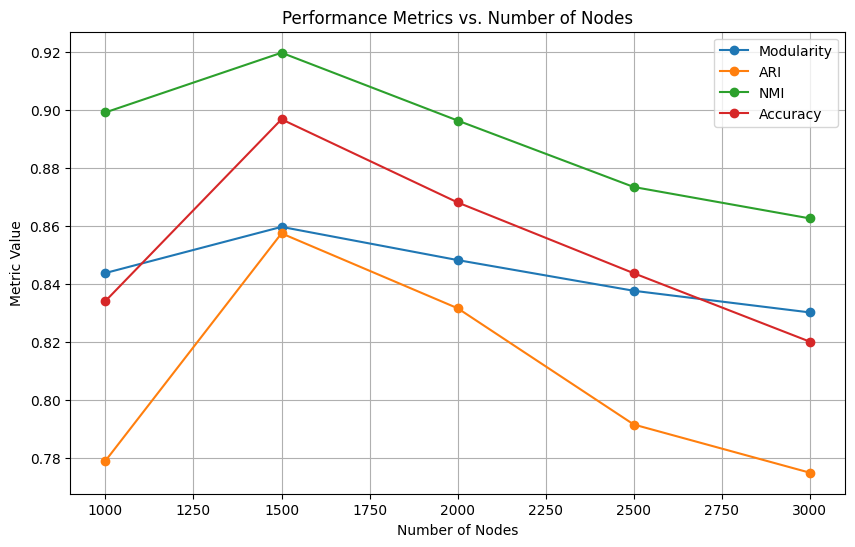

In [55]:
# Group 1: Varying number of nodes
num_nodes_values = [1000, 1500, 2000, 2500, 3000]
min_community_values = [i//40 for i in num_nodes_values]
max_community_values = [i//20 for i in num_nodes_values]
actual_num_communities = []
estimated_num_communities = []
modularity_values = []
ari_values = []
nmi_values = []
acc_values = []
for num_nodes, min_community, max_community in zip(num_nodes_values, min_community_values, max_community_values):
    # print(f"\nGenerating LFR benchmark graph with min_community={min_community}, max_community={max_community}")

    G, adj_matrix, community_assignment = generate_lfr_benchmark_graph(
        n=num_nodes, tau1=3, tau2=1.5, mu=0.1, avg_degree=4, max_degree=15,
        min_community=min_community, max_community=max_community, seed=42
    )

    unique_values = np.unique(community_assignment)
    actual_num_communities.append(len(unique_values))
    num_communities = estimate_number_of_communities(adj_matrix, 4)
    estimated_num_communities.append(num_communities)
    
    features_matrix = np.eye(adj_matrix.shape[0])  # Identity matrix of size n x n
    communities,P=CDNMF(adj_matrix,features_matrix,k=num_communities, num_iterations=100, beta=0.5)
    calc_modularity = calculate_modularity(adj_matrix, communities)
    ari = adjusted_rand_score(community_assignment, communities)
    nmi = normalized_mutual_info_score(community_assignment, communities)
    acc = best_accuracy(community_assignment, communities)
    modularity_values.append(calc_modularity)
    ari_values.append(ari)
    nmi_values.append(nmi)
    acc_values.append(acc)

# # Plot the results
# plt.figure(figsize=(10, 6))
# plt.plot(num_nodes_values, actual_num_communities, 'o-', label='Actual')
# plt.plot(num_nodes_values, estimated_num_communities, 'o-', label='Estimated')
# plt.xlabel('Number of Nodes')
# plt.ylabel('Number of Communities')
# plt.title('Number of Communities vs. Number of Nodes')
# plt.legend()
# plt.grid(True)
# plt.show()

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(num_nodes_values, modularity_values, 'o-', label='Modularity')
plt.plot(num_nodes_values, ari_values, 'o-', label='ARI')
plt.plot(num_nodes_values, nmi_values, 'o-', label='NMI')
plt.plot(num_nodes_values, acc_values, 'o-', label='Accuracy')
plt.xlabel('Number of Nodes')
plt.ylabel('Metric Value')
plt.title('Performance Metrics vs. Number of Nodes')
plt.legend()
plt.grid(True)
plt.show()

# # Group 2: Varying mixing parameter mu
# mu_values = [0.1, 0.15, 0.2, 0.25, 0.3]
# actual_num_communities = []
# estimated_num_communities = []
# modularity_values = []
# ari_values = []
# nmi_values = []
# acc_values = []
# for mu in mu_values:
#     G, adj_matrix, community_assignment = generate_lfr_benchmark_graph(
#         n=3000, tau1=3, tau2=1.5, mu=mu, avg_degree=4, max_degree=15,
#         min_community=50, max_community=100, seed=42
#     )

#     unique_values = np.unique(community_assignment)
#     actual_num_communities.append(len(unique_values))
#     num_communities = estimate_number_of_communities(adj_matrix, 4)
#     estimated_num_communities.append(num_communities)

#     features_matrix = np.eye(adj_matrix.shape[0])  # Identity matrix of size n x n
#     communities,P=CDNMF(adj_matrix,features_matrix,k=num_communities, num_iterations=100, beta=0.5)
#     calc_modularity = calculate_modularity(adj_matrix, communities)
#     ari = adjusted_rand_score(community_assignment, communities)
#     nmi = normalized_mutual_info_score(community_assignment, communities)
#     acc = best_accuracy(community_assignment, communities)
#     modularity_values.append(calc_modularity)
#     ari_values.append(ari)
#     nmi_values.append(nmi)
#     acc_values.append(acc)

# # Plot the results
# plt.figure(figsize=(10, 6))
# plt.plot(mu_values, actual_num_communities, 'o-', label='Actual')
# plt.plot(mu_values, estimated_num_communities, 'o-', label='Estimated')
# plt.xlabel('Mixing Parameter (mu)')
# plt.ylabel('Number of Communities')
# plt.title('Number of Communities vs. Mixing Parameter')
# plt.legend()
# plt.grid(True)
# plt.show()

# # Plot the results
# plt.figure(figsize=(10, 6))
# plt.plot(mu_values, modularity_values, 'o-', label='Modularity')
# plt.plot(mu_values, ari_values, 'o-', label='ARI')
# plt.plot(mu_values, nmi_values, 'o-', label='NMI')
# plt.plot(mu_values, acc_values, 'o-', label='Accuracy')
# plt.xlabel('Mixing Parameter (mu)')
# plt.ylabel('Metric Value')
# plt.title('Performance Metrics vs. Mixing Parameter')
# plt.legend()
# plt.grid(True)
# plt.show()

In [48]:
G, adj_matrix, community_assignment = generate_lfr_benchmark_graph(
        n=3000, tau1=3, tau2=1.5, mu=0.2, avg_degree=4, max_degree=15,
        min_community=50, max_community=100, seed=42
    )

unique_values = np.unique(community_assignment)
features_matrix = np.eye(adj_matrix.shape[0])  # Identity matrix of size n x n
communities,P=CDNMF(adj_matrix,features_matrix,k=len(unique_values), num_iterations=100, beta=0.5)
# print(f"Calculated Community Assignment:\n", communities)
orig_modularity = calculate_modularity(adj_matrix, community_assignment)
calc_modularity = calculate_modularity(adj_matrix, communities)
ari = adjusted_rand_score(community_assignment, communities)
nmi = normalized_mutual_info_score(community_assignment, communities)
acc = best_accuracy(community_assignment, communities)
print(f"Original modularity: {orig_modularity}")
print(f"Calculated modularity: {calc_modularity}")
print(f'Adjusted Rand Index: {ari}')
print(f'Normalized Mutual Information: {nmi}')
print(f'Accuracy: {acc}')

Estimated number of communities: 44
Rank of the Laplacian matrix: 2999
Total eigenvalues: 3000
Zero eigenvalues: 1
Negative eigenvalues: 1496
Rank of the Laplacian matrix: 1504
Total eigenvalues: 3000
Zero eigenvalues: 1496
Negative eigenvalues: 752
Rank of the Laplacian matrix: 1504
Total eigenvalues: 3000
Zero eigenvalues: 1496
Negative eigenvalues: 766
Rank of the Laplacian matrix: 1504
Total eigenvalues: 3000
Zero eigenvalues: 1496
Negative eigenvalues: 762
Rank of the Laplacian matrix: 1504
Total eigenvalues: 3000
Zero eigenvalues: 1496
Negative eigenvalues: 763
Objective function value after 1 iterations: 154.3483537299863
Objective function value after 11 iterations: 103.87514730766534
Objective function value after 21 iterations: 103.57770025898735
Objective function value after 31 iterations: 103.55133505266902
Objective function value after 41 iterations: 103.53130702173912
Objective function value after 51 iterations: 103.51807247836584
Objective function value after 61 iter